EDA Assignment: Does More Health Spending = Longer Life?
**Name:** Muhammad Haris Yasir___________________  |  **Date:** 13/9/26__________  |  ⏱️ *Target time: ~1 hour*

---
### 🤔 The big question
Every country spends money on healthcare — some spend *a lot* more than others. It seems obvious that **spending more should mean people live longer**... right?

**Your job:** use EDA to find out if that's actually true. This is an **open-ended** assignment — there's no single "correct" cell to fill in. You explore the data, follow what's interesting, and back up your answer with charts.

> 🎯 **Before you touch the data, write your gut guess here:**
> *Do you think the country that spends the MOST on healthcare also lives the longest? (yes / no / not sure):* __________

No, I think higher healthcare spending will generally be associated with longer life expectancy. Healthcare spending is important, but life expectancy can also be influenced by other factors such as the happiness index, economic conditions, political stability, poverty rate, education level, lifestyle, diet, environmental quality, income inequality, access to healthcare, and overall living conditions. For example Michael Jackson.

**The dataset:** health spending per person vs life expectancy, for 6 wealthy countries, 1970–2020 (real OECD-style data, built into seaborn — loads offline).

### 📤 What to hand in
Answer every ✍️ **question** in your own words, and make sure your charts are clear (titles + labels). Marks reward **insight and evidence**, not fancy code. Run *Kernel → Restart & Run All* before submitting.

## Step 0 — Setup & Load *(warm-up)*

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = sns.load_dataset('healthexp')   # Year, Country, Spending_USD, Life_Expectancy
print("Shape:", df.shape)
df.head()

Shape: (274, 4)


,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9


In [ ]:
# TODO: Get to know the data. Show:
#   - which countries are included  (HINT: df['Country'].unique())
print("Countries:", df['Country'].unique())

#   - the range of years            (HINT: df['Year'].min(), df['Year'].max())
print("Year range:", df['Year'].min(), "to", df['Year'].max())

#   - a quick df.describe()
df.describe()

Countries: ['Germany' 'France' 'Great Britain' 'Japan' 'USA' 'Canada']
Year range: 1970 to 2020


,Year,Spending_USD,Life_Expectancy
count,274.000000,274.000000,274.000000
mean,1996.992701,2789.338905,77.909489
std,14.180933,2194.939785,3.276263
min,1970.000000,123.993000,70.600000
25%,1985.250000,1038.357000,75.525000
50%,1998.000000,2295.578000,78.100000
75%,2009.000000,4055.610000,80.575000
max,2020.000000,11859.179000,84.700000


## Task 1 — The Core Relationship *(≈15 min)*
*Is there a link between how much a country spends and how long people live?*

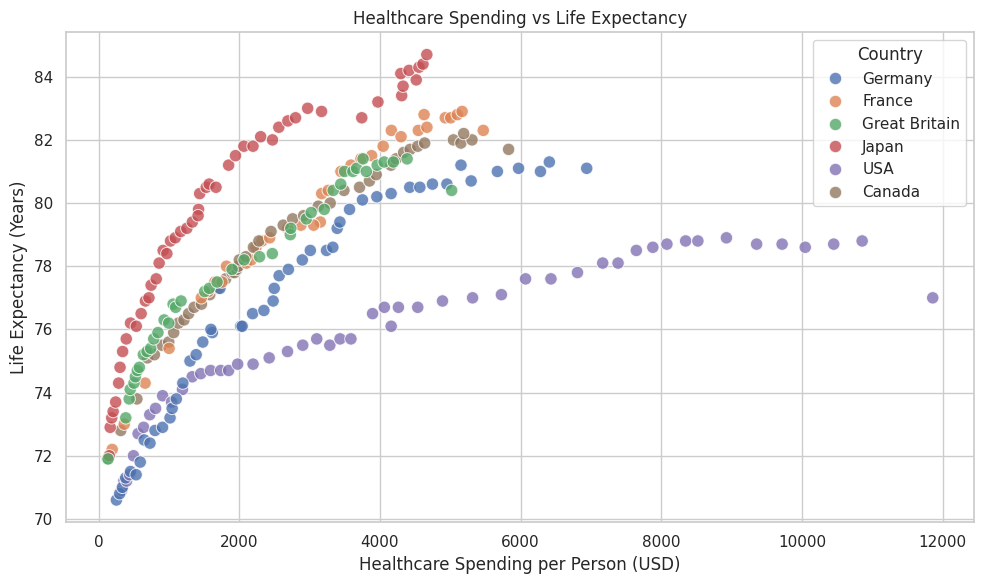

In [ ]:
# TODO: Make a scatter plot of Spending_USD (x) vs Life_Expectancy (y).
# Colour the points by Country so you can see who's who.
# HINT: sns.scatterplot(data=df, x='Spending_USD', y='Life_Expectancy', hue='Country')

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Spending_USD',
    y='Life_Expectancy',
    hue='Country',
    s=80,
    alpha=0.8
)

plt.title('Healthcare Spending vs Life Expectancy')
plt.xlabel('Healthcare Spending per Person (USD)')
plt.ylabel('Life Expectancy (Years)')
plt.legend(title='Country')
plt.tight_layout()

plt.show()

**✍️ Q1:** In general, as spending goes up, does life expectancy go up, down, or stay flat? Would you call the relationship strong or weak?
*Your answer:* _______________

In general, as healthcare spending goes up, life expectancy also tends to go up. I would describe the relationship as moderately strong and positive, because the points generally rise from left to right, but they do not follow a perfect straight line. Some countries spend much more without having equally higher life expectancy.

*Optional hint for evidence:* `df['Spending_USD'].corr(df['Life_Expectancy'])` gives a number from −1 to +1.

In [ ]:
correlation = df['Spending_USD'].corr(df['Life_Expectancy'])
print("Correlation:", correlation)

Correlation: 0.5794304588530952


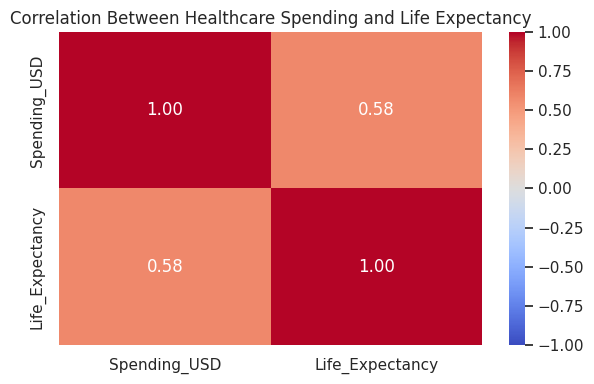

In [ ]:
# Correlation heatmap for healthcare spending and life expectancy

correlation_matrix = df[['Spending_USD', 'Life_Expectancy']].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Correlation Between Healthcare Spending and Life Expectancy')
plt.tight_layout()
plt.show()

## Task 2 — Find the Odd One Out *(≈15 min)*
*Every good analyst looks for what breaks the pattern.*

           Country  Spending_USD  Life_Expectancy
273            USA     11859.179             77.0
269        Germany      6938.983             81.1
268         Canada      5828.324             81.7
270         France      5468.418             82.3
271  Great Britain      5018.700             80.4
272          Japan      4665.641             84.7


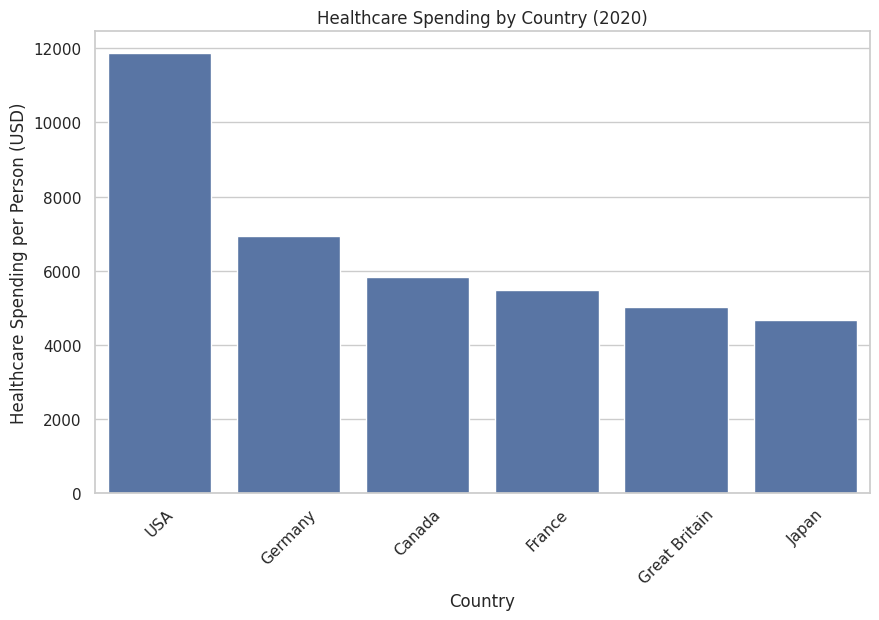

In [ ]:
# TODO: Look at just the most recent year in the data.
# HINT: latest = df[df['Year'] == df['Year'].max()]
latest = df[df['Year'] == df['Year'].max()]

# Then sort by Spending_USD to see who spends the most vs who lives longest.
latest_sorted = latest.sort_values('Spending_USD', ascending=False)

print(latest_sorted[['Country', 'Spending_USD', 'Life_Expectancy']])

# A bar chart of spending per country (for that year) makes it obvious.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=latest_sorted,
    x='Country',
    y='Spending_USD'
)

plt.title(f"Healthcare Spending by Country ({df['Year'].max()})")
plt.xlabel('Country')
plt.ylabel('Healthcare Spending per Person (USD)')
plt.xticks(rotation=45)

plt.show()

**✍️ Q2:** Which country **spends the most** per person? Which country **lives the longest**? Are they the same country? *(This is the heart of the assignment — what surprised you?)*
*Your answer:* _______________

The USA spends the most on healthcare per person, while Japan has the highest life expectancy. They are not the same country. I found this surprising because the USA spends much more than the other countries, but its life expectancy is lower than Japan’s. This shows that spending more on healthcare does not automatically mean people will live longer.

## Task 3 — Change Over Time *(≈15 min)*
*Has the story always been this way, or did it change?*

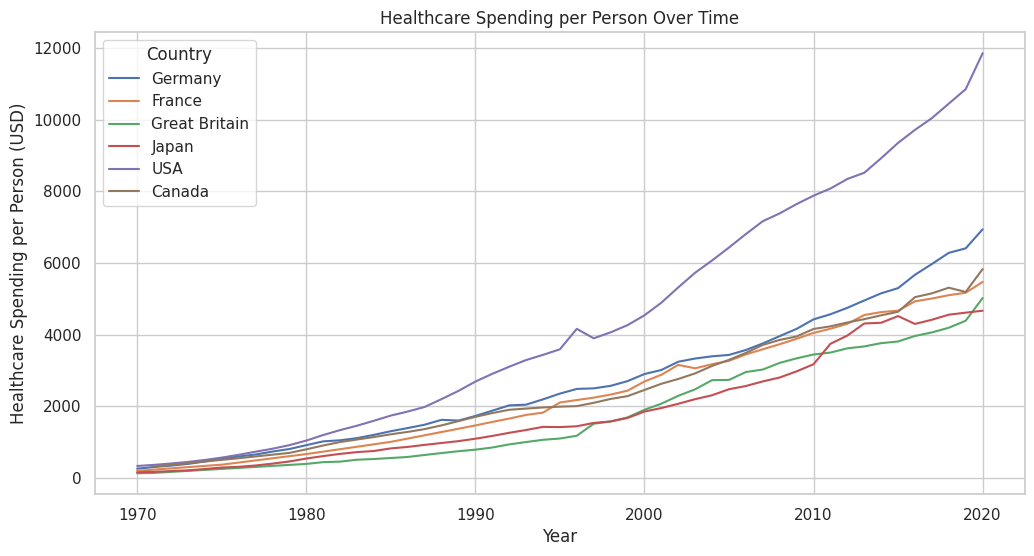

In [ ]:
# TODO: Plot how ONE thing changed from 1970 to 2020, for every country.
# Pick either Spending_USD OR Life_Expectancy over Year, with one line per country.
# HINT: sns.lineplot(data=df, x='Year', y='Spending_USD', hue='Country')

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x='Year',
    y='Spending_USD',
    hue='Country'
)

plt.title('Healthcare Spending per Person Over Time')
plt.xlabel('Year')
plt.ylabel('Healthcare Spending per Person (USD)')

plt.show()

**✍️ Q3:** Describe one clear trend you see over time. Does one country pull away from the others at some point?
*Your answer:* _______________

Healthcare spending generally increases over time for all countries. However, the **USA pulls away from the other countries**, especially in the later years, as its spending rises much faster. By the end of the period, the USA is spending substantially more per person than the other countries.

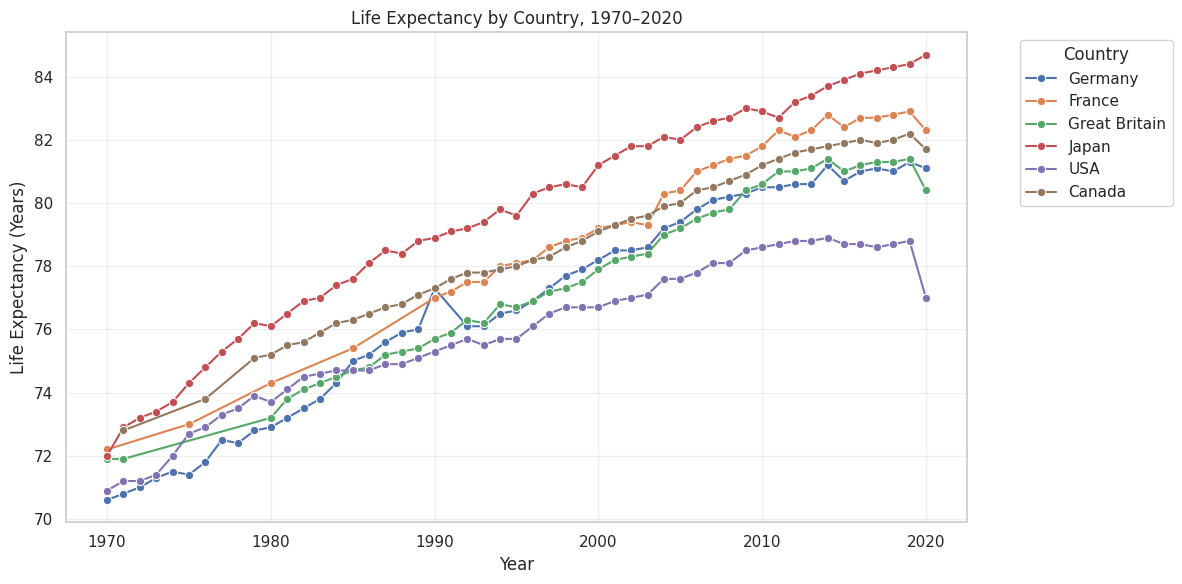

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x='Year',
    y='Life_Expectancy',
    hue='Country',
    marker='o'
)

plt.title('Life Expectancy by Country, 1970–2020')
plt.xlabel('Year')
plt.ylabel('Life Expectancy (Years)')
plt.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Task 4 — Your Own Investigation *(≈10 min)*  🔍 *open-ended*
Ask **your own** question about this data and answer it with **one** chart. Ideas (or invent your own):
- Who improved their life expectancy the *most* since 1970?
- Which country gets the most "life expectancy per dollar" (best value)?
- Is any country's life expectancy *flattening* even as spending climbs?

,Country,first,last,Improvement
0,Japan,72.0,84.7,12.7
1,Germany,70.6,81.1,10.5
2,France,72.2,82.3,10.1
3,Canada,72.8,81.7,8.9
4,Great Britain,71.9,80.4,8.5
5,USA,70.9,77.0,6.1


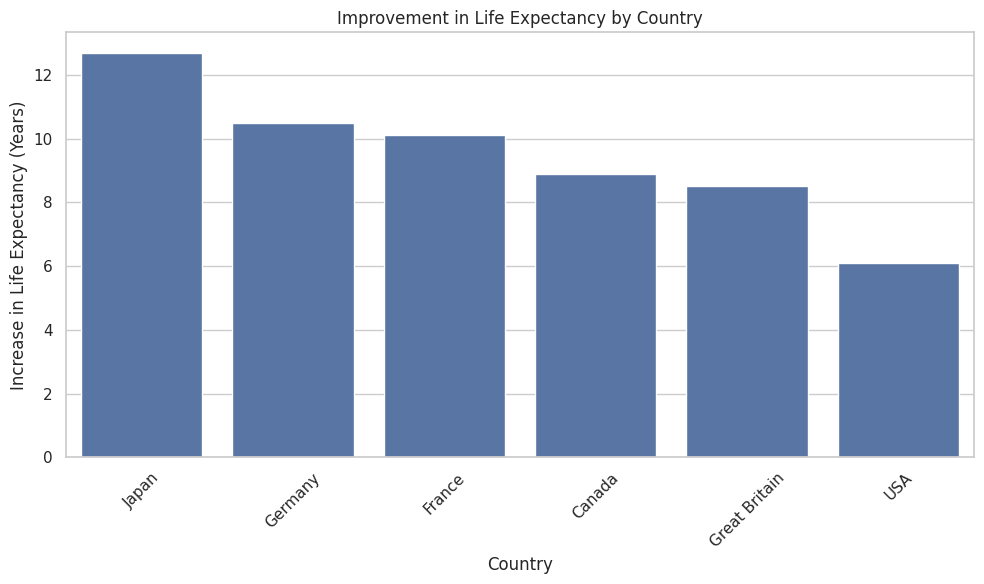

In [ ]:
# TODO: Your question, your chart. Write your question as a comment first, then the code.
# My question: ...
# Which country improved its life expectancy the most over the period covered by the dataset?

life_change = (
    df.sort_values('Year')
      .groupby('Country')['Life_Expectancy']
      .agg(['first', 'last'])
)

# Calculate improvement in years
life_change['Improvement'] = (
    life_change['last'] - life_change['first']
)

# Sort countries from highest to lowest improvement
life_change = (
    life_change
    .sort_values('Improvement', ascending=False)
    .reset_index()
)

# Display results
display(life_change)

# Create chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=life_change,
    x='Country',
    y='Improvement'
)

plt.title('Improvement in Life Expectancy by Country')
plt.xlabel('Country')
plt.ylabel('Increase in Life Expectancy (Years)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**✍️ Q4:** What did *your* chart show? State your finding in one sentence.
*Your answer:* _______________

The chart shows that **Japan had the largest improvement in life expectancy**, increasing by about **12.7 years** over the period covered by the dataset.

## 🏁 Your Verdict
Answer the assignment's big question in **2–3 sentences**, using what your charts showed. Then look back: **was your gut guess from the top right or wrong?**

**✍️ Final verdict:**

> _______________________________________________
>
> _______________________________________________

More healthcare spending is generally linked with higher life expectancy, but spending the most does not guarantee that people live the longest. The USA spends the most per person, while Japan has the highest life expectancy, so other factors clearly matter too such as lifestyle, education, poverty, economic conditions, healthcare efficiency, and social conditions.

> *My original guess was (right / wrong) because: _______________*

My original guess was right because I predicted that the country spending the most would not necessarily have the longest life expectancy.

---
✅ *Before submitting:* every ✍️ answered, charts have titles/labels, ran Restart & Run All with no errors. Nice work! 🎉